<a href="https://colab.research.google.com/github/SolJosefinaMercado/AprendizajeAutomatico1/blob/main/ISSD_Taller_redes_neuronales_sklearn_clasificaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller: Redes neuronales con scikit-learn
### Clasificación desde un enfoque de "caja negra"

**Curso:** Minería de Datos

---

## ¿Qué vamos a aprender?

Al terminar este taller vas a poder:

1. Entrenar una **red neuronal** (perceptrón multicapa) para **clasificación** con `scikit-learn`.
2. Preparar los datos correctamente para que la red funcione (¡esto es más importante de lo que parece!).
3. **Analizar resultados**: métricas, gráficos, errores, variabilidad y qué variables importan.
4. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` y `RandomizedSearchCV`).
5. Aplicar todo lo anterior por tu cuenta en dos problemas nuevos.

## Cómo trabajar con este notebook

- Ejecutá las celdas **en orden** (`Shift + Enter`). Muchas dependen de las anteriores.
- Los bloques con 🤔 **Para pensar** son preguntas para que discutas con tus compañeros antes de seguir.
- Al final hay **actividades** para resolver solos/as reutilizando lo que vimos.
- Este notebook está pensado para **Google Colab**: guardá tu propia copia con `Archivo → Guardar una copia en Drive`.
- No pasa nada si algo falla: ¡equivocarse es parte del proceso! Podés volver a ejecutar cualquier celda.

## 📑 Contenido

| Parte | Tema |
|---|---|
| 0 | La idea general: ¿qué es una red neuronal (MLP)? |
| 1 | Preparación del entorno |
| 2 | **Regresión**: predecir el consumo de combustible de autos |
| 3 | **Clasificación**: identificar especies de pingüinos |
| 4 | Resumen y buenas prácticas |
| 5 | **Actividades** para resolver por tu cuenta |

---
# Parte 0 · La idea general

## ¿Qué es un perceptrón multicapa (MLP)?

Un **MLP** (*Multi-Layer Perceptron*) es una red neuronal formada por capas de "neuronas" conectadas entre sí:

```
 Variables de           Capas ocultas            Salida
  entrada          (aquí "ocurre la magia")
                                                   
   x1 ──┐          ┌─ ○ ─┐      ┌─ ○ ─┐
   x2 ──┼────────► │  ○  │ ───► │  ○  │ ───────►  predicción
   x3 ──┤          │  ○  │      └─ ○ ─┘
   ...  ┘          └─ ○ ─┘
```

Cada neurona hace algo muy simple: **combina las entradas con unos pesos, suma y aplica una función de activación** (por ejemplo, ReLU). Al apilar muchas neuronas y varias capas, la red puede aprender relaciones **no lineales** complejas.

El entrenamiento consiste en **ajustar los pesos** para que las predicciones se parezcan cada vez más a los valores reales. Esto se hace de forma iterativa (descenso de gradiente): en cada *época* la red ve los datos, mide su error y corrige un poquito los pesos.

## El enfoque "caja negra"

En este taller **no vamos a programar la red ni a derivar ecuaciones**. Vamos a tratarla como una **caja negra configurable**:

- 📥 Le damos datos (bien preparados).
- 🎛️ Ajustamos unos "botones" (**hiperparámetros**).
- 📊 Evaluamos qué tan bien predice y qué variables influyen.

> Esto **no** significa usarla a ciegas: significa saber **qué botones existen, qué hacen y cómo verificar que el resultado es confiable**.

## Los "botones" principales de `MLPRegressor` / `MLPClassifier`

| Hiperparámetro | ¿Qué controla? | Valores típicos |
|---|---|---|
| `hidden_layer_sizes` | Arquitectura: cuántas capas ocultas y cuántas neuronas en cada una. `(64, 32)` = 2 capas, de 64 y 32 neuronas | `(16,)`, `(64,)`, `(64, 32)` |
| `activation` | Función de activación de las capas ocultas | `"relu"`, `"tanh"`, `"logistic"` |
| `solver` | Algoritmo de optimización | `"adam"` (por defecto), `"lbfgs"` (bueno en datasets chicos), `"sgd"` |
| `alpha` | **Regularización** (penaliza pesos grandes → evita sobreajuste) | `0.0001` a `1` |
| `learning_rate_init` | Tamaño de los "pasos" de aprendizaje (solvers `adam`/`sgd`) | `0.0001` a `0.1` |
| `max_iter` | Máximo de épocas de entrenamiento | `500`, `1000`, `2000` |
| `early_stopping` | Corta el entrenamiento cuando deja de mejorar en validación | `True` / `False` |
| `random_state` | Semilla aleatoria (los pesos iniciales son aleatorios) | cualquier entero |

---
# Parte 1 · preparación del entorno

Importamos las librerías que vamos a usar. En Google Colab ya vienen instaladas, no hace falta instalar nada.

In [ ]:
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPRegressor, MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# pero en la sección 7.1 los vamos a reactivar a propósito para entender qué significan.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"  # también en procesos paralelos

print("¡Todo listo! 🎉")

¡Todo listo! 🎉


---
# Parte 3 · Clasificación con `MLPClassifier`

Ya conocemos el flujo. Ahora lo vamos a aplicar a **clasificación**, donde en vez de predecir un número, predecimos una **categoría**. Vas a ver que el código es muy parecido.

## El problema: ¿de qué especie es este pingüino?

Usaremos el dataset público **Palmer Penguins**: medidas de pingüinos de tres especies (*Adelie*, *Chinstrap* y *Gentoo*) de las islas del archipiélago Palmer, en la Antártida.

> **Variable objetivo (categórica):** `species` → problema de **clasificación multiclase** (3 clases).

In [ ]:
url_pinguinos = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_ping = pd.read_csv(url_pinguinos)

print(f"Dimensiones: {df_ping.shape}")
df_ping.head()

Dimensiones: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
# Valores faltantes y distribución de las clases
print("Valores faltantes por columna:")
print(df_ping.isna().sum())

print("\nDistribución de especies:")
print(df_ping["species"].value_counts())

Valores faltantes por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Distribución de especies:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


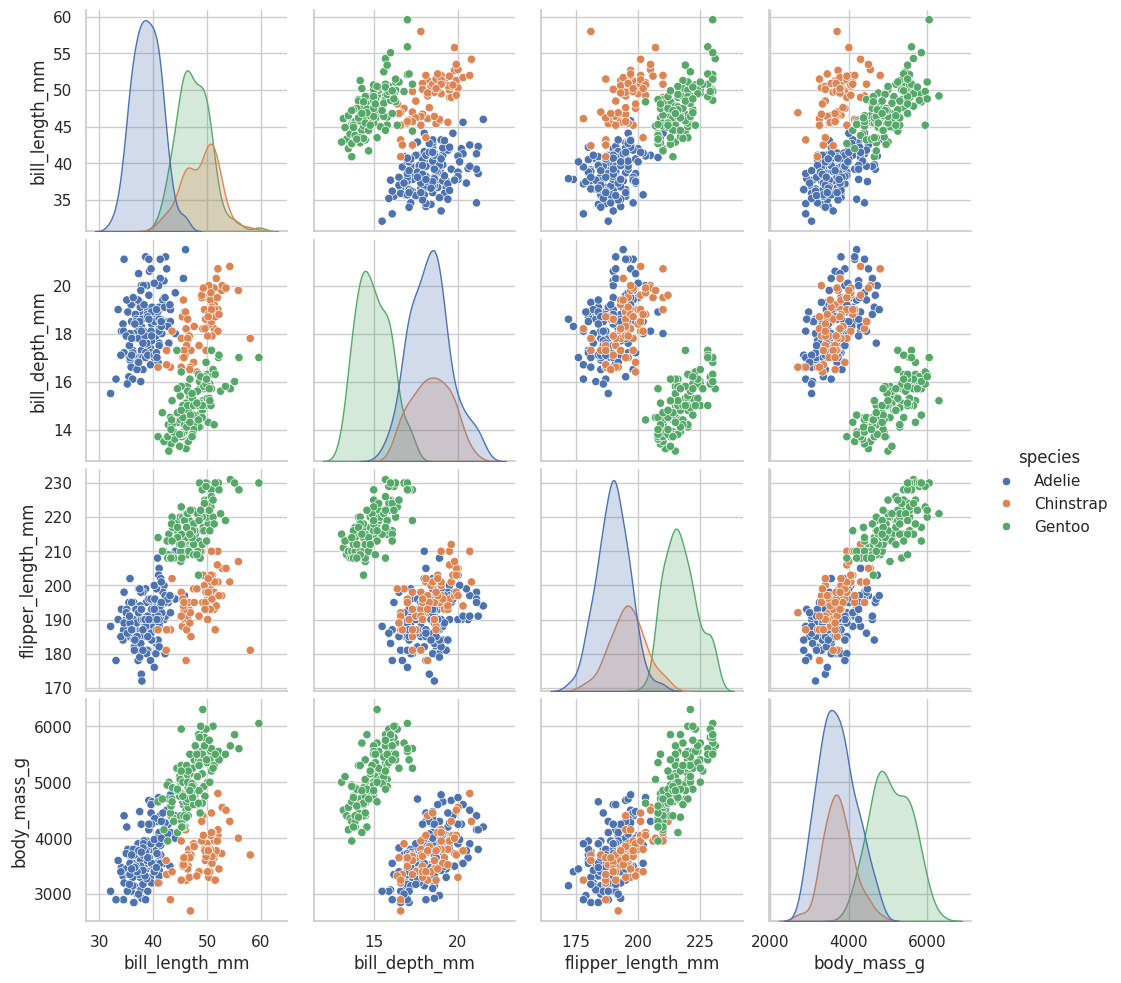

In [ ]:
# Relación entre variables, coloreando por especie
sns.pairplot(df_ping, hue="species", vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
plt.show()

### 🤔 Para pensar
- ¿Qué pares de variables separan mejor las tres especies?
- ¿Cuánta dificultad esperás que tenga este problema para un clasificador?

## Paso 1 · Preparación y división de datos

Igual que antes, pero con dos diferencias:

- Las variables categóricas (`island`, `sex`) también tienen faltantes, así que las imputamos con la **moda** (`most_frequent`).
- Al dividir usamos **`stratify=y`**: así entrenamiento y prueba mantienen **la misma proporción de cada especie**. Es muy recomendable en clasificación.

In [ ]:
X_p = df_ping.drop(columns=["species"])
y_p = df_ping["species"]

X_ent_p, X_prueba_p, y_ent_p, y_prueba_p = train_test_split(
    X_p, y_p,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y_p          # mantiene las proporciones de cada clase
)

print("Proporción de clases en entrenamiento:")
print(y_ent_p.value_counts(normalize=True).round(3))

Proporción de clases en entrenamiento:
species
Adelie       0.444
Gentoo       0.360
Chinstrap    0.196
Name: proportion, dtype: float64


In [ ]:
cols_num_p = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cols_cat_p = ["island", "sex"]

preprocesador_clf = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_p),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),     # moda para categóricas
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_p)
])

## Paso 2 · Baselines y primera red neuronal

Comparamos:
- **Dummy**: siempre predice la clase más frecuente.
- **Regresión logística**: clasificador lineal simple.
- **MLP**: nuestra red neuronal.

In [ ]:
# Función para evaluar clasificadores
def evaluar_clasificacion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_ent, pred_ent),
        "accuracy_prueba": accuracy_score(y_prueba, pred_prueba),
        "F1_macro_prueba": f1_score(y_prueba, pred_prueba, average="macro"),
    }

resultados_clf = []

# Baseline 1: Dummy
dummy_clf = Pipeline([("prep", preprocesador_clf), ("modelo", DummyClassifier(strategy="most_frequent"))])
dummy_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(dummy_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Dummy (clase mayoritaria)"))

# Baseline 2: Regresión logística
logit_clf = Pipeline([("prep", preprocesador_clf), ("modelo", LogisticRegression(max_iter=1000))])
logit_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(logit_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Regresión logística"))

# Nuestra primera red neuronal para clasificar
mlp_clf = Pipeline([
    ("prep", preprocesador_clf),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])
mlp_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(mlp_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP inicial (32,16)"))

pd.DataFrame(resultados_clf)

,modelo,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
0,Dummy (clase mayoritaria),0.444,0.435,0.202
1,Regresión logística,0.993,1.000,1.000
2,"MLP inicial (32,16)",1.000,0.986,0.983


### ¿Cómo leer las métricas de clasificación?

- **Accuracy (exactitud)**: proporción de aciertos totales. Es intuitiva, pero puede engañar si las clases están desbalanceadas.
- **F1 macro**: promedia el F1 (balance entre precisión y sensibilidad) de cada clase **dándoles el mismo peso**. Es más justa cuando hay clases minoritarias.
- Compará siempre contra el **Dummy**: nos dice el "piso" que hay que superar.

### 🤔 Para pensar



¿ por qué es importante considerar otras métricas además del Accuracy?

## Paso 3 · Analizar resultados de clasificación

### Reporte por clase y matriz de confusión

- El **reporte de clasificación** muestra precisión, sensibilidad (*recall*) y F1 **para cada clase**.
- La **matriz de confusión** muestra qué clases se confunden entre sí: filas = clase real, columnas = clase predicha. Lo ideal es que solo la diagonal tenga valores.

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



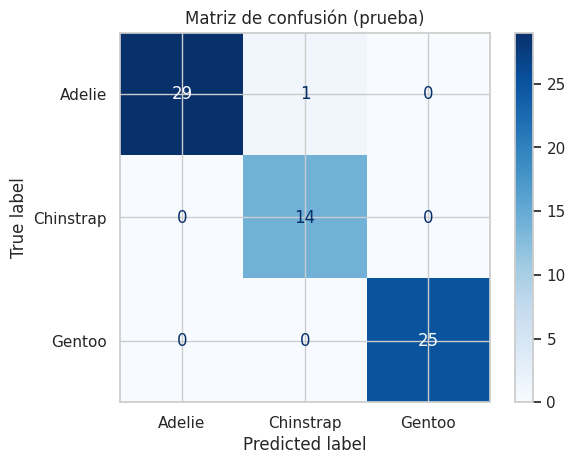

In [ ]:
pred_p = mlp_clf.predict(X_prueba_p)

print(classification_report(y_prueba_p, pred_p))

ConfusionMatrixDisplay.from_estimator(mlp_clf, X_prueba_p, y_prueba_p, cmap="Blues")
plt.title("Matriz de confusión (prueba)")
plt.show()

### Probabilidades de cada clase

Un `MLPClassifier` no solo dice "esta es la clase X": también nos da **la probabilidad estimada de cada clase** con `predict_proba`. Esto es muy útil para saber **qué tan seguro** está el modelo.

In [ ]:
# Probabilidades para los primeros 5 pingüinos de prueba
probabilidades = pd.DataFrame(
    mlp_clf.predict_proba(X_prueba_p.head()),
    columns=mlp_clf.classes_           # los nombres de las clases
)
probabilidades["predicha"] = mlp_clf.predict(X_prueba_p.head())
probabilidades["real"] = y_prueba_p.head().values
probabilidades.round(3)

,Adelie,Chinstrap,Gentoo,predicha,real
0,0.984,0.012,0.004,Adelie,Adelie
1,0.999,0.001,0.000,Adelie,Adelie
2,0.003,0.001,0.996,Gentoo,Gentoo
3,0.001,0.000,0.999,Gentoo,Gentoo
4,0.007,0.993,0.000,Chinstrap,Chinstrap


In [ ]:
# ¿Dónde se equivoca el modelo? Miramos los casos mal clasificados
errores = X_prueba_p.copy()
errores["real"] = y_prueba_p
errores["predicha"] = pred_p
errores[errores["real"] != errores["predicha"]]

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,real,predicha
37,Dream,42.2,18.5,180.0,3550.0,FEMALE,Adelie,Chinstrap


### 🤔 Para pensar
- ¿Qué tan difícil resultó este problema? ¿Cuánto mejora la red respecto de la regresión logística?
- Si el modelo casi no se equivoca, ¿cuánto margen de mejora nos queda para el ajuste de hiperparámetros?

## Paso 4 · Ajuste de hiperparámetros con `RandomizedSearchCV`

Cuando hay **muchos hiperparámetros**, una grilla completa se vuelve enorme. `RandomizedSearchCV` es una alternativa: en vez de probar todas las combinaciones, **sortea `n_iter` combinaciones al azar** de las distribuciones que le indicamos. Suele encontrar buenas configuraciones con mucho menos costo.

Para parámetros continuos como `alpha` usamos `loguniform`: sortea valores en escala logarítmica (tiene sentido porque nos interesa probar 0.0001, 0.001, 0.01..., no solo valores entre 0 y 1).

Además usamos **`StratifiedKFold`** para que cada partición de la validación cruzada conserve las proporciones de clases, y optimizamos **`f1_macro`**.

In [ ]:
# Distribuciones / listas de valores a explorar
distribuciones = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16), (64, 32)],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": loguniform(1e-5, 1e0),                # entre 0.00001 y 1
    "mlp__learning_rate_init": loguniform(1e-4, 1e-1),  # (solo afecta al solver "adam")
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

busqueda_clf = RandomizedSearchCV(
    estimator=mlp_clf,
    param_distributions=distribuciones,
    n_iter=20,                  # cantidad de combinaciones aleatorias a probar
    cv=validacion,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=SEMILLA,
    verbose=1
)

busqueda_clf.fit(X_ent_p, y_ent_p)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_clf.best_params_.items():
    print(f"  {parametro}: {valor}")
print(f"\nMejor F1 macro en validación cruzada: {busqueda_clf.best_score_:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros:
  mlp__activation: tanh
  mlp__alpha: 2.8381292701126715e-05
  mlp__hidden_layer_sizes: (64, 32)
  mlp__learning_rate_init: 0.0003972110727381913
  mlp__solver: adam

Mejor F1 macro en validación cruzada: 0.997


In [ ]:
res_c = pd.DataFrame(busqueda_clf.cv_results_)
columnas_c = ["param_mlp__hidden_layer_sizes", "param_mlp__activation", "param_mlp__solver",
              "param_mlp__alpha", "mean_test_score", "std_test_score", "rank_test_score"]

res_c.sort_values("rank_test_score")[columnas_c].head(8)

,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__solver,param_mlp__alpha,mean_test_score,std_test_score,rank_test_score
6,"(64, 32)",tanh,adam,2.838e-05,0.997,0.006,1
7,"(32,)",relu,adam,1.707e-05,0.997,0.006,1
14,"(64, 32)",tanh,adam,4.298e-01,0.997,0.006,1
15,"(32, 16)",tanh,adam,4.233e-04,0.997,0.006,1
12,"(64, 32)",tanh,lbfgs,1.336e-03,0.997,0.006,1
13,"(16,)",relu,lbfgs,7.046e-01,0.997,0.006,1
9,"(32, 16)",tanh,lbfgs,3.335e-04,0.997,0.006,1
16,"(64,)",tanh,adam,6.703e-01,0.997,0.006,1


> 💡 **Observación importante:** en este dataset, muchas configuraciones distintas logran resultados casi idénticos (¡y muy altos!). Cuando el problema es "fácil" y el modelo simple ya rinde muy bien, **ajustar hiperparámetros aporta poco**: las diferencias entre configuraciones quedan dentro del ruido (`std_test_score`). En problemas más difíciles, el ajuste suele marcar más diferencia.

In [ ]:
mejor_clf = busqueda_clf.best_estimator_

resultados_clf.append(evaluar_clasificacion(mejor_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP optimizado (RandomSearch)"))
pd.DataFrame(resultados_clf).set_index("modelo")

,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
modelo,,,
Dummy (clase mayoritaria),0.444,0.435,0.202
Regresión logística,0.993,1.000,1.000
"MLP inicial (32,16)",1.000,0.986,0.983
MLP optimizado (RandomSearch),1.000,0.986,0.983


## Paso 5 · ¿Qué variables usa el modelo para decidir?

Repetimos la **importancia por permutación**, ahora con `accuracy` como métrica.

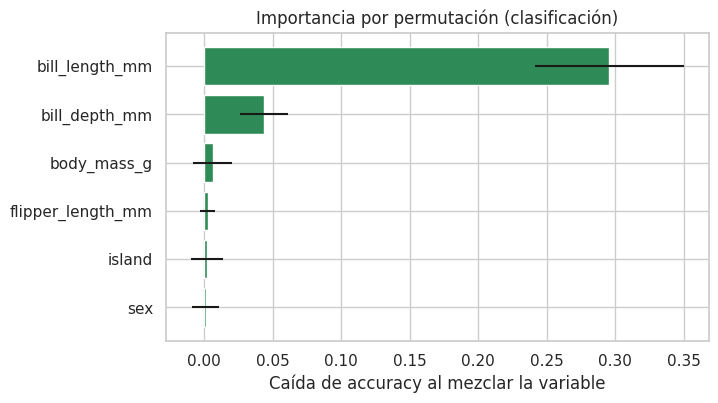

In [ ]:
imp_c = permutation_importance(
    mejor_clf, X_prueba_p, y_prueba_p,
    n_repeats=30, scoring="accuracy", random_state=SEMILLA
)

importancias_c = pd.DataFrame({
    "variable": X_prueba_p.columns,
    "caida_accuracy": imp_c.importances_mean,
    "desvio": imp_c.importances_std
}).sort_values("caida_accuracy")

plt.figure(figsize=(7, 4))
plt.barh(importancias_c["variable"], importancias_c["caida_accuracy"], xerr=importancias_c["desvio"], color="seagreen")
plt.xlabel("Caída de accuracy al mezclar la variable")
plt.title("Importancia por permutación (clasificación)")
plt.show()

---
# Parte 4 · Resumen y buenas prácticas

## La receta que usamos (sirve para regresión y clasificación)

1. **Explorar** los datos (tipos, faltantes, distribuciones).
2. **Dividir** en entrenamiento y prueba (con `stratify` si es clasificación).
3. **Preprocesar dentro de un `Pipeline`**: imputar → escalar numéricas → codificar categóricas.
4. Entrenar **modelos de referencia** (Dummy, lineal/logístico) para tener con qué comparar.
5. Entrenar la **red neuronal** y **analizar resultados** (métricas, gráficos, errores).
6. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` / `RandomizedSearchCV`), usando **solo** el conjunto de entrenamiento.
7. **Evaluar una sola vez** en el conjunto de prueba.
8. **Interpretar** con importancia por permutación y **reportar** con honestidad (¡incluida la variabilidad!).

## ✅ Checklist rápido

| Situación | Qué hacer |
|---|---|
| `ConvergenceWarning` (o `n_iter_` igual a `max_iter`) | Aumentar `max_iter`, verificar que las variables estén escaladas, probar otro `solver` |
| Rendimiento muy bueno en entrenamiento y malo en prueba (sobreajuste) | Aumentar `alpha`, reducir neuronas, usar `early_stopping=True`, conseguir más datos |
| Rendimiento malo en ambos (subajuste) | Más neuronas/capas, más épocas, mejores variables |
| Resultados que cambian mucho entre corridas | Fijar `random_state`, comparar con validación cruzada, repetir con varias semillas |
| Dataset muy pequeño | Probar `solver="lbfgs"` |
| Clases desbalanceadas | No confiar solo en accuracy: mirar F1 macro, recall por clase y matriz de confusión |

## Ventajas y limitaciones de los MLP

** Ventajas:** capturan relaciones no lineales e interacciones complejas sin que las especifiquemos.

**Limitaciones:** son sensibles a la escala, tienen muchos hiperparámetros, son poco interpretables y suelen no superar a otros métodos (como bosques aleatorios o *gradient boosting*) en datos tabulares pequeños. ¡Siempre comparalos!

>  `scikit-learn` es ideal para aprender y para problemas tabulares pequeños o medianos. Para redes profundas, imágenes, texto o mucho volumen de datos se usan librerías como **PyTorch** o **TensorFlow/Keras**.

---
# Parte 5. Actividades

Ahora es tu turno. **Reutilizá el código de las partes anteriores** (copiar, pegar y adaptar es totalmente válido). Cada actividad indica qué parte del taller te sirve de guía.

> En las celdas de código encontrarás pistas como comentarios. Las celdas de texto "**Tu respuesta:**" son para que escribas tus conclusiones (doble clic para editar).

---
## Actividad 2 · Clasificación: ¿quién sobrevivió al Titanic?

**Dataset:** `titanic` (público, repositorio de datos de `seaborn`). Cada fila es un pasajero y la variable objetivo es `survived` (1 = sobrevivió, 0 = no sobrevivió).

 **Objetivo:** construir un clasificador binario con una red neuronal, analizar sus errores y ajustar hiperparámetros.

 **Te sirve de guía:** Parte 3 (Clasificación).

Este dataset es **más difícil** que el de pingüinos: tiene más faltantes y no hay una separación tan clara entre clases. ¡Aquí el ajuste y el análisis sí van a importar!

In [ ]:
url_titanic = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_tit = pd.read_csv(url_titanic)

df_tit.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.283,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.100,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.050,S,Third,man,True,NaN,Southampton,no,True


**2.1 · Exploración y selección de variables.**

**Cuidado con las "trampas":** el dataset incluye columnas redundantes o que **revelan directamente la respuesta**. Por ejemplo, `alive` contiene "yes"/"no" y es equivalente a `survived`. Usarla como predictora sería un caso de **fuga de información (*data leakage*)**: el modelo tendría un rendimiento espectacular... pero completamente inútil en la vida real.

Otras columnas (`class`, `who`, `adult_male`, `embark_town`, `alone`) repiten información de columnas que ya existen, y `deck` tiene demasiados faltantes.

Trabajá **solo** con estas variables predictoras:

- Numéricas: `pclass`, `age`, `sibsp`, `parch`, `fare`
- Categóricas: `sex`, `embarked`

Explorá: ¿cuál es la proporción de sobrevivientes? ¿Cuántos faltantes tiene cada variable elegida? ¿Cómo cambia la supervivencia según `sex` y `pclass`?

In [ ]:
# Tu código aquí
# Pista: df_tit["survived"].value_counts(normalize=True)
#        sns.barplot(data=df_tit, x="sex", y="survived", hue="pclass")

**Tu respuesta (2.1):**

*(¿Qué variables parecen más relacionadas con la supervivencia?)*

**2.2 · División y preprocesamiento.**
- Dividí en entrenamiento y prueba (80 / 20) **con `stratify`**.
- Armá un `ColumnTransformer` que, para las numéricas, imputa con la mediana y estandariza; y para las categóricas, imputa con la moda y aplica `OneHotEncoder`.

In [ ]:
# Tu código aquí
# Pista: Paso 1 de la Parte 3.

**2.3 · Modelos de referencia y primera red neuronal.**
Entrená un `DummyClassifier`, una `LogisticRegression` y un `MLPClassifier` (por ejemplo con `hidden_layer_sizes=(32, 16)`). Compará *accuracy* y *F1 macro* en entrenamiento y prueba usando `evaluar_clasificacion`.

In [ ]:
# Tu código aquí
# Pista: Paso 2 de la Parte 3.

**2.4 · Análisis de errores.**
Mostrá el reporte de clasificación y la matriz de confusión del MLP. Respondé:
- ¿Se equivoca más al predecir a los que sobrevivieron o a los que no?
- En un problema real, ¿qué tipo de error te parecería más grave? ¿Por qué depende del contexto?

In [ ]:
# Tu código aquí
# Pista: Paso 3 de la Parte 3.

**Tu respuesta (2.4):**

*(escribí acá tus conclusiones)*

**2.5 · Ajuste de hiperparámetros.**
Usá `RandomizedSearchCV` con `StratifiedKFold` (5 particiones) y `scoring="f1_macro"` (o `"accuracy"`, si preferís justificar). Explorá al menos `hidden_layer_sizes`, `alpha` y `activation`. Evaluá el mejor modelo en prueba.

Luego respondé: **¿la mejora respecto del MLP inicial es "real" o está dentro del ruido?** (Pista: compará la diferencia con `std_test_score`).

In [ ]:
# Tu código aquí
# Pista: Paso 4 de la Parte 3.

**Tu respuesta (2.5):**

*(escribí acá tus conclusiones)*

**2.6 · Importancia de variables y umbral de decisión.**

**(a)** Calculá la importancia por permutación. ¿Coincide con lo que viste en la exploración?

**(b)** Por defecto, el modelo clasifica como "sobrevivió" si la probabilidad supera **0.5**. Pero podemos elegir otro **umbral**. Con `predict_proba`, calculá la *precisión* y el *recall* de la clase 1 usando umbrales de 0.3, 0.5 y 0.7. ¿Qué ocurre con cada métrica al subir el umbral?

```python
from sklearn.metrics import precision_score, recall_score

probabilidad_sobrevivir = modelo.predict_proba(X_prueba)[:, 1]   # columna de la clase 1
for umbral in [0.3, 0.5, 0.7]:
    pred = (probabilidad_sobrevivir >= umbral).astype(int)
    # calculá precision_score(y_prueba, pred) y recall_score(y_prueba, pred)
```

In [ ]:
# Tu código aquí

**Tu respuesta (2.6):**

*(escribí acá tus conclusiones)*

---
## Actividad 3 · Curva de validación: sobreajuste vs. subajuste

Usando el modelo de la Actividad 2 (Titanic) y la técnica del **Paso 7.2** de la Parte 2, construí una **curva de validación** para el hiperparámetro **`alpha`** (regularización) con valores como `[1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]`.

Usá `scoring="accuracy"` y graficá el puntaje de entrenamiento y de validación (con el eje X en escala logarítmica).

Respondé:
1. ¿Con qué valores de `alpha` hay **sobreajuste**? ¿Y **subajuste**?
2. ¿Qué valor elegirías? ¿Coincide con el que encontró la búsqueda aleatoria?

In [ ]:
# Tu código aquí
# Pista: validation_curve(..., param_name="mlp__alpha", param_range=[...], scoring="accuracy")
#        plt.xscale("log")

**Tu respuesta (Actividad 3):**

*(escribí acá tus conclusiones)*

---
## Actividad 4 · Reflexión final

Respondé brevemente (2-4 líneas cada una) con tus propias palabras:

4. En el dataset de pingüinos el ajuste de hiperparámetros casi no cambió el resultado. ¿Por qué? ¿Cuándo esperarías que el ajuste sí importe mucho?
5. Si tuvieras que explicarle a alguien sin conocimientos técnicos **por qué no basta con mirar el accuracy**, ¿qué ejemplo le darías?

**Tus respuestas:**

1.
2.
3.
4.
5.

---
# ¡Felicitaciones!

Completaste una introducción completa al uso de redes neuronales en `scikit-learn`. Recordá la idea central:

> **Una red neuronal no es magia: es un modelo más que hay que preparar bien, evaluar con honestidad y comparar contra alternativas simples.**

### Para seguir explorando
- Documentación de redes neuronales en scikit-learn: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>
- Guía de validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Ajuste de hiperparámetros: <https://scikit-learn.org/stable/modules/grid_search.html>
- Importancia por permutación: <https://scikit-learn.org/stable/modules/permutation_importance.html>
- Datasets usados: [Auto MPG (UCI)](https://archive.ics.uci.edu/dataset/9/auto+mpg), [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), y los datasets de ejemplo de [seaborn-data](https://github.com/mwaskom/seaborn-data).